# **# Student Dropout Prediction**
Dataset: `student_dropout_dataset_cleaned.csv`

# 10. EDA
Visualizations selected based on the features that show a clear difference between students who dropped out and those who stayed.

In [ ]:
import pandas as pd
df = pd.read_csv("/content/student_dropout_dataset_cleaned.csv")
df.head()

,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,1,22,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,2,20,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,3,22,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,4,24,Male,29740.5,Yes,4.00,82.2,2,38.6,No,No,5.5,1.78,1.77,1.77,Year 1,CS,High School,1
4,5,20,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df["Status"] = df["Dropout"].map({0: "Stayed", 1: "Dropped out"})
pal = {"Stayed": "#2563eb", "Dropped out": "#dc2626"}
sns.set_theme(style="whitegrid", font_scale=1.05)

## 10.1 CGPA Distribution by Dropout Status

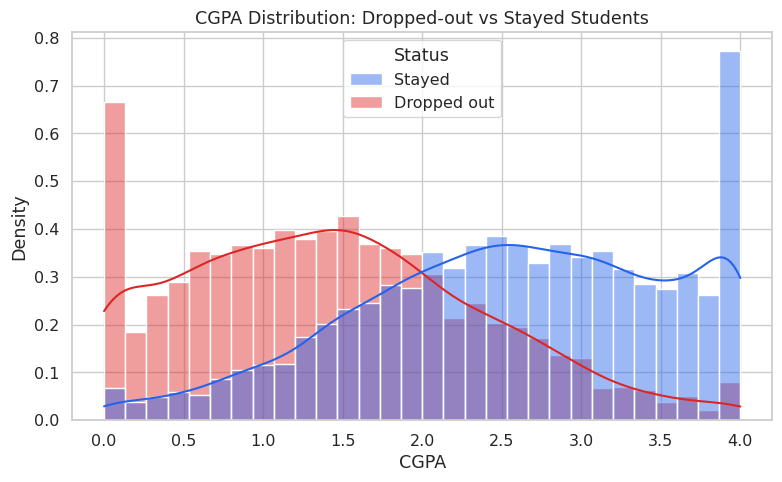

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="CGPA", hue="Status", palette=pal, kde=True,
             stat="density", common_norm=False, bins=30, alpha=0.45)
plt.title("CGPA Distribution: Dropped-out vs Stayed Students")
plt.tight_layout()
plt.show()

10.1: Students who dropped out are concentrated at lower CGPA values (mean 1.44 vs 2.56), while students who stayed are concentrated at higher values, making CGPA the strongest separator.

## 10.2 Stress Index by Dropout Status

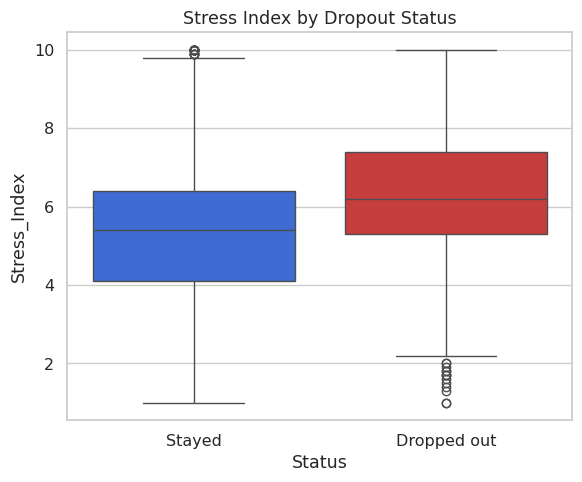

In [ ]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="Status", y="Stress_Index", hue="Status", palette=pal,
            order=["Stayed", "Dropped out"], legend=False)
plt.title("Stress Index by Dropout Status")
plt.tight_layout()
plt.show()

10.2: Dropped-out students show a higher median Stress Index than students who stayed (about 6.2 vs 5.4).

## 10.3 Dropout Rate by Attendance Band

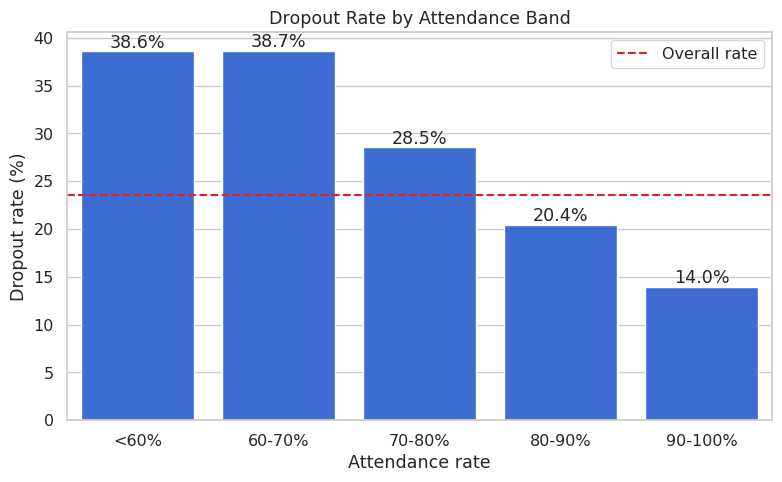

In [ ]:
df["Attendance_Band"] = pd.cut(df["Attendance_Rate"], [0, 60, 70, 80, 90, 100],
                               labels=["<60%", "60-70%", "70-80%", "80-90%", "90-100%"])
rate = df.groupby("Attendance_Band", observed=True)["Dropout"].mean() * 100

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=rate.index.astype(str), y=rate.values, color="#2563eb")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.axhline(df["Dropout"].mean() * 100, color="#dc2626", ls="--", label="Overall rate")
plt.ylabel("Dropout rate (%)")
plt.xlabel("Attendance rate")
plt.title("Dropout Rate by Attendance Band")
plt.legend()
plt.tight_layout()
plt.show()

10.3: Dropout rate decreases steadily as attendance increases, from about 39% below 70% attendance to 14% above 90%.

## 10.4 Attendance Rate Distribution

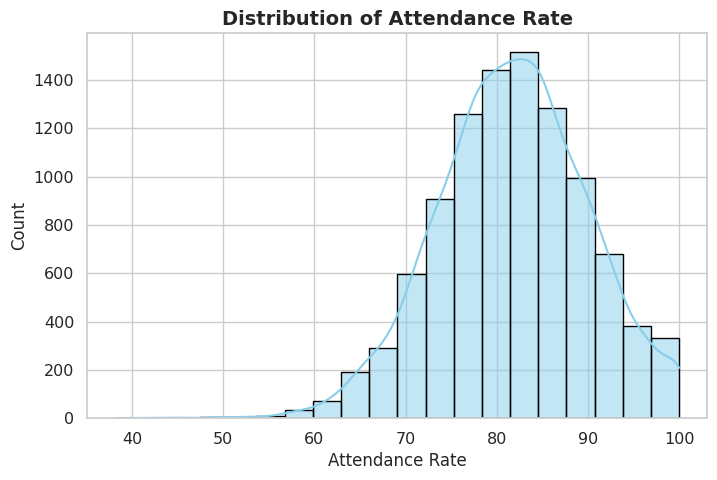

In [ ]:
plt.figure(figsize=(8, 5))

# Plotting the Distribution (Histogram + KDE Density Curve)
sns.histplot(df['Attendance_Rate'], kde=True, bins=20, color='skyblue', edgecolor='black')

# Headlines
plt.title('Distribution of Attendance Rate', fontsize=14, fontweight='bold')
plt.xlabel('Attendance Rate', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.show()

10.4: The attendance rate distribution shows that the vast majority of data is concentrated above 60%, with very few cases below this threshold, justifying <60% as the starting band.

## 10.5 Dropout Rate by Student Circumstances

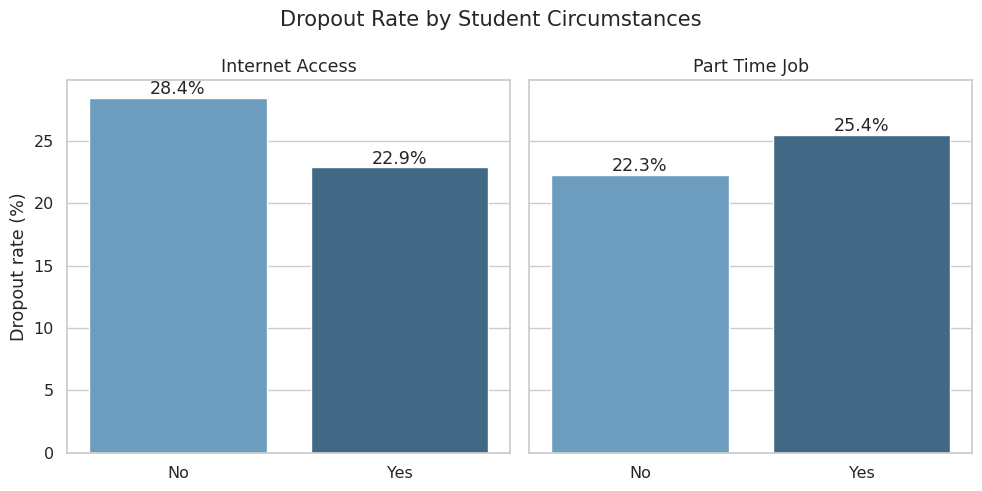

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, col in zip(axes, ["Internet_Access", "Part_Time_Job"]):
    r = df.groupby(col)["Dropout"].mean() * 100
    sns.barplot(x=r.index, y=r.values, hue=r.index, palette="Blues_d", legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%")
    ax.set_title(col.replace("_", " "))
    ax.set_ylabel("Dropout rate (%)")
    ax.set_xlabel("")
fig.suptitle("Dropout Rate by Student Circumstances")
plt.tight_layout()
plt.show()

10.5: Students without internet access and those with a part-time job show slightly higher dropout rates, though the differences are small.

## 10.6 Class Imbalance Check (Target: `Dropout`)

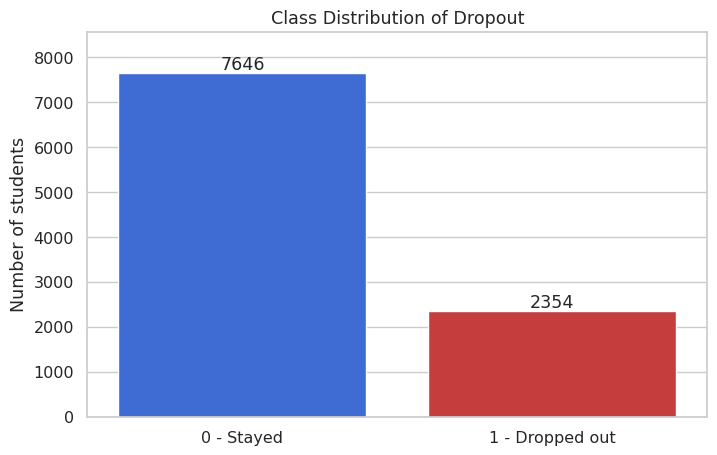

In [ ]:
# Calculating the values ​​required for the drawing
counts = df["Dropout"].value_counts().sort_index()
imbalance_table = pd.DataFrame({"Count": counts})
imbalance_table.index = ["0 - Stayed", "1 - Dropped out"]

# Drawing a Bar Chart
plt.figure(figsize=(8, 5))
dropout_count = sns.barplot(
    x=imbalance_table.index,
    y=imbalance_table["Count"],
    hue=imbalance_table.index,
    palette=["#2563eb", "#dc2626"],
)

for c in dropout_count.containers:
  dropout_count.bar_label(c)

# Additional space for numbers
dropout_count.set_ylim(0, imbalance_table["Count"].max() * 1.12)
plt.title("Class Distribution of Dropout")
plt.ylabel("Number of students")
plt.xlabel("")
plt.show()

10.6: The target is imbalanced with 7,646 students who stayed and 2,354 who dropped out, making accuracy misleading; therefore, models must be evaluated using Precision, Recall, and F1-score.

## 10.7 Correlation Heatmap

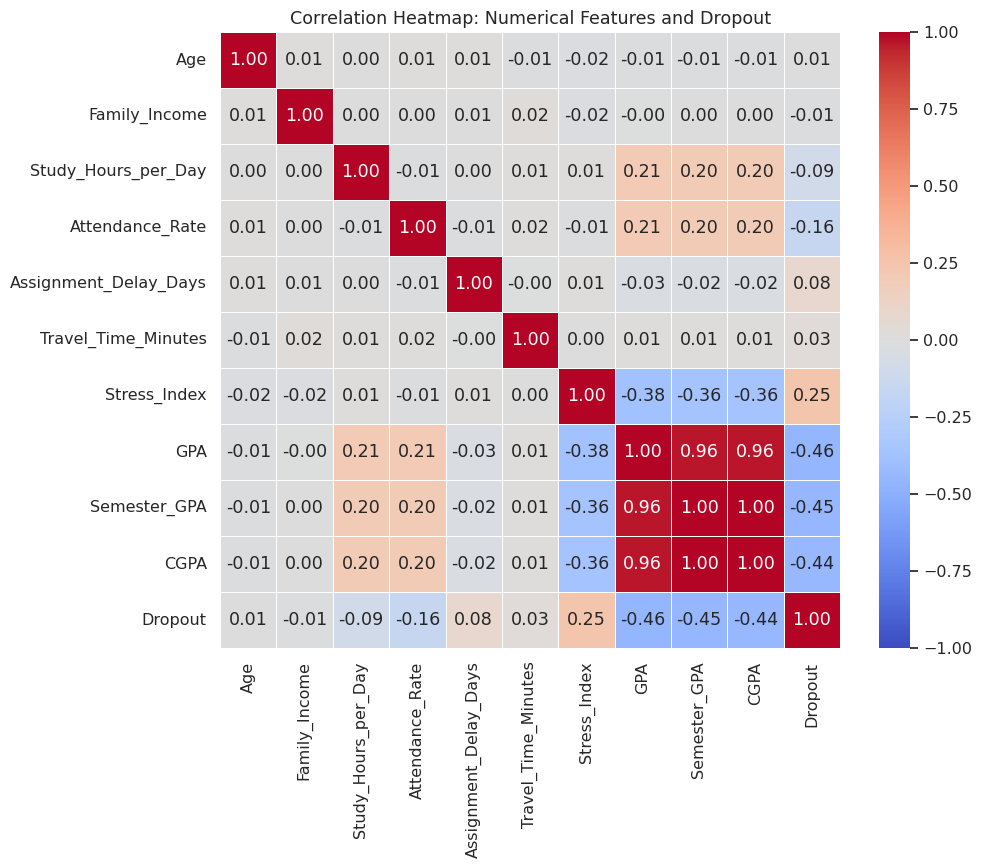

In [ ]:
# Numerical columns + the target
corr_cols = ["Age", "Family_Income", "Study_Hours_per_Day", "Attendance_Rate", "Assignment_Delay_Days",
             "Travel_Time_Minutes", "Stress_Index", "GPA", "Semester_GPA", "CGPA", "Dropout"]

corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5) # Center colormap at 0 with fixed correlation limits (-1 to 1)
plt.title("Correlation Heatmap: Numerical Features and Dropout")
plt.show()

10.7:

* Key Dropout Drivers: Academic performance metrics (GPA, Semester_GPA, and CGPA) show the strongest negative correlation with Dropout (~ -0.44 to -0.46), indicating higher grades significantly reduce dropout risk. Conversely, Stress_Index shows a positive correlation (+0.25).

* Weak Features: Age, Family_Income, and Travel_Time show almost no correlation with Dropout.

* Higher grade-> fewer dropouts
* High stress-> lower grades


# 11. Data Split (70 / 15 / 15)

##11.1 Features and target

In [ ]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X = df.drop(columns=["Student_ID", "Dropout", "Status", "Attendance_Band"])
y = df["Dropout"]
print(X.shape, y.shape)
print(y.value_counts(normalize=True).round(3))

(10000, 17) (10000,)
Dropout
0    0.765
1    0.235
Name: proportion, dtype: float64


##11.2 Final Split


Stratified on `Dropout`, so all three sets keep the same dropout rate.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp)

for name, part in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11} rows={len(part):>5}  ({len(part)/len(y):.0%})  dropout rate={part.mean():.3f}")

assert not (set(X_train.index) & set(X_val.index))
assert not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))
print("No overlap between sets")

X_train.assign(Dropout=y_train).to_csv("train.csv", index=False)
X_val.assign(Dropout=y_val).to_csv("val.csv", index=False)
X_test.assign(Dropout=y_test).to_csv("test.csv", index=False)
print("Saved: train.csv, val.csv, test.csv")

Train       rows= 7000  (70%)  dropout rate=0.235
Validation  rows= 1500  (15%)  dropout rate=0.235
Test        rows= 1500  (15%)  dropout rate=0.235
No overlap between sets
Saved: train.csv, val.csv, test.csv


#12. Feature engineering & Scaling & Encoding

## 12.1 Feature engineering
Two new features, each built from one column with a fixed rule, so nothing is learned from the data.

* `Low_Attendance`: 1 if attendance is below 70%. Section 10.3 showed the highest dropout rate in this group.
* `High_Stress`: 1 if Stress_Index is 7 or higher. Section 10.2 showed higher stress among dropped-out students.

In [ ]:
for part in (X_train, X_val, X_test):
    part["Low_Attendance"] = (part["Attendance_Rate"] < 70).astype(int)
    part["High_Stress"] = (part["Stress_Index"] >= 7).astype(int)

X_train[["Low_Attendance", "High_Stress"]].describe().loc[["count", "mean"]].round(3)

,Low_Attendance,High_Stress
count,7000.000,7000.000
mean,0.076,0.202


Check on the training set that both features separate dropouts.

In [ ]:
check = X_train.assign(Dropout=y_train)

for col in ["Low_Attendance", "High_Stress"]:
    print(col)
    print(check.groupby(col)["Dropout"].agg(["mean", "count"]).round(3))
    print()

Low_Attendance
                 mean  count
Low_Attendance              
0               0.222   6471
1               0.395    529

High_Stress
              mean  count
High_Stress              
0            0.196   5585
1            0.392   1415



## 12.2 Encoding
* Gender, Internet_Access, Part_Time_Job and Scholarship have two values, so they are mapped to 0/1.
* Semester and Parental_Education have an order, so they are mapped to ordered numbers.
* Department has no order, so it is one-hot encoded.

The mappings are fixed rules, so they are applied the same way to all three sets.

In [ ]:
def encode(data):
    data = data.copy()
    data["Gender"] = data["Gender"].map({"Male": 0, "Female": 1})
    for col in ["Internet_Access", "Part_Time_Job", "Scholarship"]:
        data[col] = data[col].map({"No": 0, "Yes": 1})
    data["Semester"] = data["Semester"].map({"Year 1": 1, "Year 2": 2, "Year 3": 3, "Year 4": 4})
    data["Parental_Education"] = data["Parental_Education"].map(
        {"High School": 1, "Bachelor": 2, "Master": 3, "PhD": 4})
    data = pd.get_dummies(data, columns=["Department"], dtype=int)
    return data

X_train_enc = encode(X_train)
X_val_enc = encode(X_val).reindex(columns=X_train_enc.columns, fill_value=0)
X_test_enc = encode(X_test).reindex(columns=X_train_enc.columns, fill_value=0)

print(X_train_enc.shape, X_val_enc.shape, X_test_enc.shape)
X_train_enc.head()

(7000, 23) (1500, 23) (1500, 23)


,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,...,CGPA,Semester,Parental_Education,Low_Attendance,High_Stress,Department_Arts,Department_Business,Department_CS,Department_Engineering,Department_Science
9252,20,0,25000.0,1,3.29,65.9,4,34.9,1,1,...,1.95,4,2,1,0,1,0,0,0,0
598,20,0,25000.0,1,3.16,79.2,4,21.9,1,0,...,3.62,3,3,0,0,0,0,0,1,0
7394,21,1,34229.0,1,5.94,62.3,2,15.5,0,0,...,2.47,2,3,1,1,0,0,0,1,0
5027,20,1,48446.0,1,5.26,100.0,2,23.3,0,1,...,1.39,4,4,0,0,1,0,0,0,0
1396,18,1,25000.0,0,2.28,96.3,0,22.3,0,0,...,3.98,1,1,0,0,0,1,0,0,0


## 12.3 Scaling
StandardScaler is fitted on the training set only, then applied to validation and test. The 0/1 and ordered columns are not scaled.

In [ ]:
from sklearn.preprocessing import StandardScaler

scale_cols = ["Age", "Family_Income", "Study_Hours_per_Day", "Attendance_Rate",
              "Assignment_Delay_Days", "Travel_Time_Minutes", "Stress_Index",
              "GPA", "Semester_GPA", "CGPA"]

scaler = StandardScaler()

X_train_scaled = X_train_enc.copy()
X_val_scaled = X_val_enc.copy()
X_test_scaled = X_test_enc.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train_enc[scale_cols])
X_val_scaled[scale_cols] = scaler.transform(X_val_enc[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test_enc[scale_cols])

X_train_scaled[scale_cols].describe().loc[["mean", "std"]].round(2)

,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA
mean,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 12.4 Final readiness check

In [ ]:
for name, part in [("Train", X_train_scaled), ("Validation", X_val_scaled), ("Test", X_test_scaled)]:
    print(f"{name:<11} {part.shape}")

assert X_train_scaled.select_dtypes(exclude="number").empty
assert X_val_scaled.select_dtypes(exclude="number").empty
assert X_test_scaled.select_dtypes(exclude="number").empty

assert X_train_scaled.isnull().sum().sum() == 0
assert X_val_scaled.isnull().sum().sum() == 0
assert X_test_scaled.isnull().sum().sum() == 0

assert list(X_train_scaled.columns) == list(X_val_scaled.columns) == list(X_test_scaled.columns)

assert not (set(X_train_scaled.index) & set(X_val_scaled.index))
assert not (set(X_train_scaled.index) & set(X_test_scaled.index))
assert not (set(X_val_scaled.index) & set(X_test_scaled.index))

assert "Dropout" not in X_train_scaled.columns
assert "Student_ID" not in X_train_scaled.columns
assert "Status" not in X_train_scaled.columns

print("All columns numeric, no missing values, no overlap, no target or ID columns")

Train       (7000, 23)
Validation  (1500, 23)
Test        (1500, 23)
All columns numeric, no missing values, no overlap, no target or ID columns


## 12.5 Before and after

In [ ]:
snapshot = pd.DataFrame({
    "Metric": ["Columns", "Text columns", "Feature scale", "Rows in train / val / test"],
    "Before": [X.shape[1], X.shape[1] - X.select_dtypes(include="number").shape[1], "Raw units",
               f"{len(X_train)} / {len(X_val)} / {len(X_test)}"],
    "After": [X_train_scaled.shape[1], X_train_scaled.shape[1] - X_train_scaled.select_dtypes(include="number").shape[1],
              "Standardized (mean 0, std 1)",
              f"{len(X_train_scaled)} / {len(X_val_scaled)} / {len(X_test_scaled)}"]
})
snapshot

,Metric,Before,After
0,Columns,17,23
1,Text columns,7,0
2,Feature scale,Raw units,"Standardized (mean 0, std 1)"
3,Rows in train / val / test,7000 / 1500 / 1500,7000 / 1500 / 1500


## 12.6 Save the final datasets

In [ ]:
X_train_scaled.assign(Dropout=y_train).to_csv("train_final.csv", index=False)
X_val_scaled.assign(Dropout=y_val).to_csv("val_final.csv", index=False)
X_test_scaled.assign(Dropout=y_test).to_csv("test_final.csv", index=False)
print("Saved: train_final.csv, val_final.csv, test_final.csv")

Saved: train_final.csv, val_final.csv, test_final.csv
